# 01. Дані та препроцесинг

In [ ]:
import json
from pathlib import Path

import numpy as np
import pandas as pd

SEED = 42
SLUG = "multiple-object-video-detection-hw-2-ucu-ai-2026"
ON_KAGGLE = Path("/kaggle/input").exists()
if ON_KAGGLE:
    DATA = next(p for p in (Path("/kaggle/input/competitions") / SLUG, Path("/kaggle/input") / SLUG) if p.exists())
else:
    DATA = Path.cwd().parent.parent / "hw2_data"

## 1. Анотації і спліт за кліпами

Train і val організатори вже поділили за кліпами. Перевіряємо, що жоден кліп не потрапив в обидві частини, що площа `area` (з неї COCO рахує AP_small) дорівнює w·h і що в межах кліпу роздільність однакова.

In [33]:
def load_split(split):
    coco = json.loads((DATA / split / "annotations_coco.json").read_text())
    images = pd.DataFrame(coco["images"]).set_index("id")
    anns = pd.DataFrame(coco["annotations"])
    boxes = pd.DataFrame(anns.pop("bbox").tolist(), columns=["x", "y", "w", "h"], index=anns.index)
    anns = anns.join(boxes).join(images[["video", "width", "height"]], on="image_id")
    classes = {c["id"]: c["name"] for c in coco["categories"]}
    return images, anns, classes


train_images, train_anns, classes = load_split("train")
val_images, val_anns, _ = load_split("val")
classes

{1: 'person',
 2: 'bicycle',
 3: 'car',
 4: 'van',
 5: 'truck',
 6: 'tricycle',
 7: 'bus',
 8: 'motor'}

In [34]:
def summary(images, anns):
    objects = anns[anns["iscrowd"] == 0]
    return pd.Series({
        "кліпів": images["video"].nunique(),
        "кадрів": len(images),
        "об'єктів": len(objects),
        "ігнорованих зон": int(anns["iscrowd"].sum()),
        "кадрів без об'єктів": len(images) - objects["image_id"].nunique(),
    })


shared = set(train_images["video"]) & set(val_images["video"])
print("Спільних кліпів train/val:", len(shared))
pd.DataFrame({"train": summary(train_images, train_anns), "val": summary(val_images, val_anns)})

Спільних кліпів train/val: 0


,train,val
кліпів,56,7
кадрів,24201,2846
об'єктів,1105516,114132
ігнорованих зон,510744,31960
кадрів без об'єктів,3,0


In [35]:
def sanity(images, anns):
    obj = anns[anns["iscrowd"] == 0]
    sizes_per_clip = images.groupby("video")[["width", "height"]].nunique()
    return pd.Series({
        "об'єктів, де area ≠ w·h": int((~np.isclose(obj["area"], obj["w"] * obj["h"], rtol=0.01)).sum()),
        "кліпів із різною роздільністю": int((sizes_per_clip > 1).any(axis=1).sum()),
    })


pd.DataFrame({"train": sanity(train_images, train_anns), "val": sanity(val_images, val_anns)})

,train,val
"об'єктів, де area ≠ w·h",0,0
кліпів із різною роздільністю,0,0


**Що бачимо:** train 56 кліпів / 24 201 кадр / 1,1 млн об'єктів, val 7 / 2 846 / 114 тис. Спільних кліпів 0. `area` = w·h для всіх об'єктів, у кожному кліпі одна роздільність.

**Що робимо:** беремо готовий поділ організаторів за кліпами (витоку між train і val немає). k-fold не робимо через бюджет GPU.

## 2. Загальна статистика

Лише об'єкти, без ігнорованих зон. Висновки робимо на train, val показуємо поруч для порівняння.

In [36]:
import matplotlib.pyplot as plt

CLASS_ORDER = list(classes.values())


def objects_table(anns, split):
    obj = anns[anns["iscrowd"] == 0].copy()
    obj["split"] = split
    obj["class"] = obj["category_id"].map(classes)
    obj["size"] = np.sqrt(obj["w"] * obj["h"])
    obj["aspect"] = obj["h"] / obj["w"]
    obj["group"] = pd.cut(obj["w"] * obj["h"], [0, 32**2, 96**2, np.inf],
                          labels=["small", "medium", "large"], right=False)
    return obj


objects = pd.concat([objects_table(train_anns, "train"), objects_table(val_anns, "val")], ignore_index=True)

### 2а. Розподіл класів

Рамки рахують той самий об'єкт на кожному кадрі. Унікальні об'єкти рахуємо за парою (кліп, `track_id`).

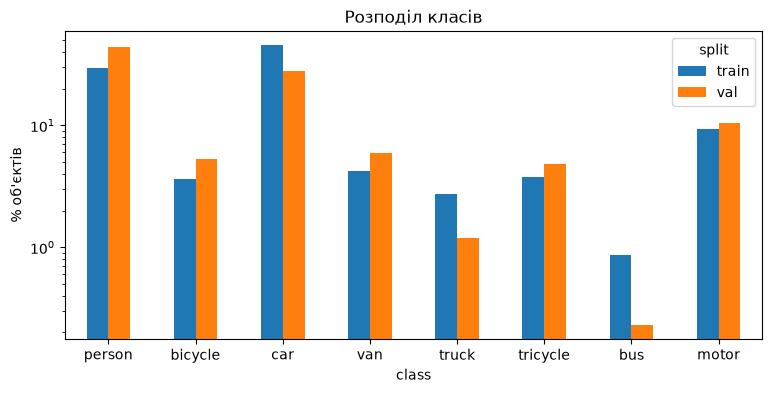

/tmp/ipykernel_133757/3679184316.py:8: Pandas4Warning: The 'lsuffix' and 'rsuffix' keywords in DataFrame.join are deprecated and will be removed in a future version. Use the 'suffixes' keyword instead.
  counts.join(shares, rsuffix=", %").join(unique, rsuffix=", унікальних")


split,train,val,"train, %","val, %","train, унікальних","val, унікальних"
class,,,,,,
person,328701,50312,29.73,44.08,2616,335
bicycle,40255,6022,3.64,5.28,299,46
car,505301,31821,45.71,27.88,2976,199
van,46940,6842,4.25,5.99,262,36
truck,30498,1359,2.76,1.19,148,8
tricycle,41349,5487,3.74,4.81,271,31
bus,9653,264,0.87,0.23,51,3
motor,102819,12025,9.30,10.54,719,100


In [37]:
counts = pd.crosstab(objects["class"], objects["split"]).reindex(CLASS_ORDER)
shares = (counts / counts.sum() * 100).round(2)
tracks = objects.drop_duplicates(["video", "track_id"])
unique = pd.crosstab(tracks["class"], tracks["split"]).reindex(CLASS_ORDER)

shares.plot.bar(logy=True, rot=0, figsize=(9, 4), ylabel="% об'єктів", title="Розподіл класів")
plt.show()
counts.join(shares, rsuffix=", %").join(unique, rsuffix=", унікальних")

**Що бачимо:**
- сильний дисбаланс: car 46%, person 30%, truck 2,8%, bus 0,9% (лише 51 унікальний автобус у train);
- один об'єкт у середньому видно на ~150 кадрах (1,1 млн рамок на ~7,3 тис. об'єктів);
- у val більше людей (44%) і менше машин (28%), ніж у train; у val лише 3 автобуси і 8 вантажівок.

**Що робимо:** AP для bus і truck на val вважаємо шумним. Повторення об'єктів по кадрах — аргумент для проріджування кадрів (секція 5).

### 2б. Розміри об'єктів

Розмір = √(w·h). Пунктир — межі COCO: small < 32 px, large > 96 px.

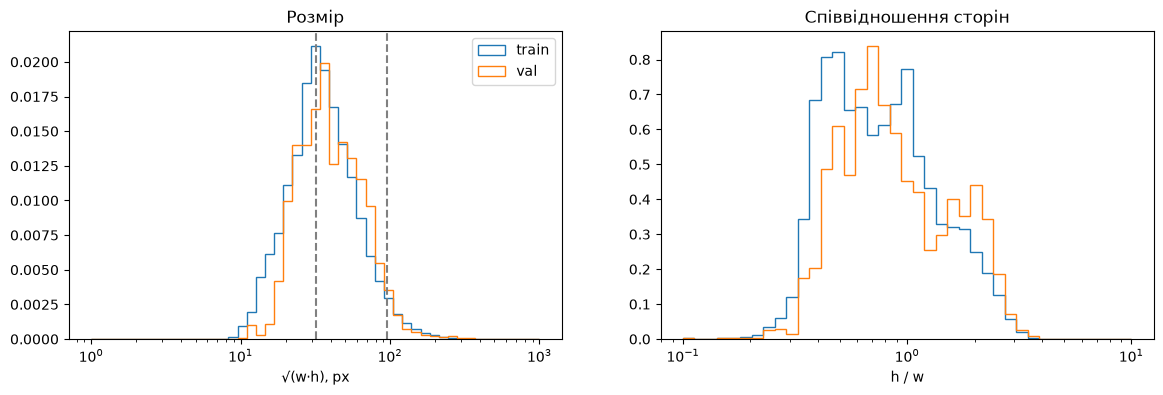

split,train,val
group,,
small,24.9,19.2
medium,63.5,69.5
large,11.6,11.3


,size,aspect
class,,
person,35.78,2.00
bicycle,41.41,1.06
car,57.01,0.80
van,49.85,0.90
truck,73.46,0.93
tricycle,54.85,0.94
bus,113.45,0.97
motor,40.21,1.24


In [38]:
fig, (ax_size, ax_aspect) = plt.subplots(1, 2, figsize=(14, 4))
for split, group in objects.groupby("split"):
    ax_size.hist(group["size"], bins=np.logspace(0, 3, 50), density=True, histtype="step", label=split)
    ax_aspect.hist(group["aspect"].clip(0.1, 10), bins=np.logspace(-1, 1, 40), density=True, histtype="step", label=split)
for edge in (32, 96):
    ax_size.axvline(edge, color="gray", linestyle="--")
ax_size.set(xscale="log", xlabel="√(w·h), px", title="Розмір")
ax_aspect.set(xscale="log", xlabel="h / w", title="Співвідношення сторін")
ax_size.legend()
plt.show()

size_groups = pd.crosstab(objects["group"], objects["split"], normalize="columns").mul(100).round(1)
train_by_class = (objects[objects["split"] == "train"]
                  .groupby("class")[["size", "aspect"]].median().round(2).reindex(CLASS_ORDER))
display(size_groups, train_by_class)

**Що бачимо:**
- small 25%, medium 64%, large 12% (train);
- медіанний розмір: person ~36 px, car ~57 px, bus ~113 px;
- форма: person витягнутий угору (h/w ≈ 2), car трохи ширший (h/w ≈ 0,8).

**Що робимо:** ці розміри й форми використаємо для якорів RetinaNet і Faster R-CNN, перерахувавши їх з урахуванням стиснення кадру.

### 2в. Об'єктів на кадр

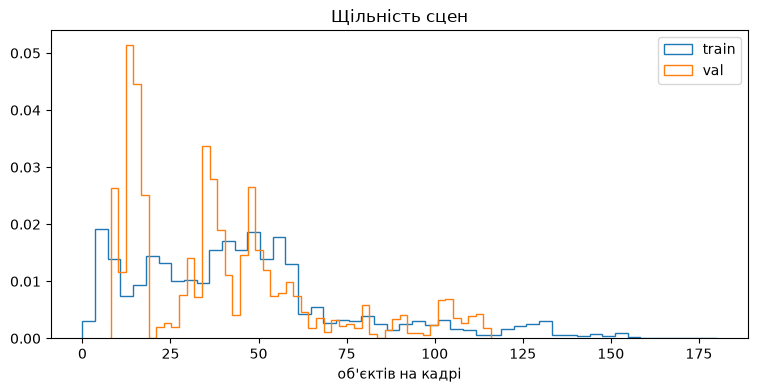

,train,val
mean,45.7,40.1
50%,43.0,37.0
95%,118.0,103.0
max,180.0,116.0


In [39]:
def objects_per_frame(images, anns):
    return anns.loc[anns["iscrowd"] == 0, "image_id"].value_counts().reindex(images.index, fill_value=0)


per_frame = {"train": objects_per_frame(train_images, train_anns), "val": objects_per_frame(val_images, val_anns)}

plt.figure(figsize=(9, 4))
for split, n in per_frame.items():
    plt.hist(n, bins=50, density=True, histtype="step", label=split)
plt.xlabel("об'єктів на кадрі")
plt.title("Щільність сцен")
plt.legend()
plt.show()

stats = {split: n.describe(percentiles=[0.5, 0.95]) for split, n in per_frame.items()}
pd.DataFrame(stats).loc[["mean", "50%", "95%", "max"]].round(1)

**Що бачимо:** у середньому 46 об'єктів на кадр, у 95% кадрів не більше 118, максимум 180.

**Що робимо:** ліміт рамок на кадр ставимо не менше 300 (у Faster R-CNN за замовчуванням 100 — замало), в оцінювачі 500.

### 2г. Об'єкти після стиснення кадру

Довша сторона кожного кадру стискається до `imgsz`. Рахуємо % об'єктів, менших за 8 px (клітинка найдрібнішої сітки ознак YOLO): спершу для всіх кадрів разом, потім для train окремо за шириною кадру.

In [40]:
WIDTH_BINS = [0, 900, 1200, 1600, 2000, np.inf]
WIDTH_LABELS = ["<900", "900–1200", "1200–1600", "1600–2000", ">2000"]

long_side = objects[["width", "height"]].max(axis=1)
tiny = pd.DataFrame({"оригінал": objects["size"] < 8})
for imgsz in (640, 960, 1280):
    tiny[str(imgsz)] = objects["size"] * imgsz / long_side < 8

display(tiny.groupby(objects["split"]).mean().mul(100).round(1).T.rename_axis("imgsz"))

train = objects["split"] == "train"
frame_width = pd.cut(objects.loc[train, "width"], WIDTH_BINS, labels=WIDTH_LABELS)
by_width = tiny[train].groupby(frame_width, observed=True).mean().mul(100).round(1)
by_width["об'єктів"] = frame_width.value_counts()
by_width.rename_axis("ширина кадру")

split,train,val
imgsz,,
оригінал,0.0,0.0
640,9.8,8.7
960,1.7,2.2
1280,0.6,0.7


,оригінал,640,960,1280,об'єктів
ширина кадру,,,,,
1200–1600,0.0,8.8,0.7,0.0,207950
1600–2000,0.0,7.1,0.4,0.0,634111
>2000,0.0,17.1,5.6,2.5,263455


**Що бачимо:**
- менших за 8 px стає: 9,8% об'єктів при `imgsz` 640, 1,7% при 960, 0,6% при 1280;
- на кадрах до 2000 px (як у тесті) при 960 лише 0,4–0,7%; проблема зосереджена в кадрах понад 2000 px, яких у тесті немає.

**Що робимо:** попередньо `imgsz` = 960; остаточно вирішимо після заміру швидкості навчання.

## 3. Відмінності між кліпами

### 3а. Характеристики кожного кліпу

Повна таблиця зберігається в `clips.csv`. У ноутбуці показано графік, розкид по кліпах і 7 val-кліпів.

In [41]:
def clip_table(images, split):
    obj = objects[objects["split"] == split]
    by_clip = obj.groupby("video")
    table = images.groupby("video").agg(width=("width", "first"), height=("height", "first"), frames=("width", "size"))
    table["split"] = split
    table["objects_per_frame"] = by_clip.size().reindex(table.index, fill_value=0) / table["frames"]
    table["median_size"] = by_clip["size"].median()
    table["small_%"] = (obj["group"] == "small").groupby(obj["video"]).mean() * 100
    top = by_clip["class"].value_counts(normalize=True).groupby(level=0).head(1).reset_index(level=1)
    table["top_class"] = top["class"]
    table["top_class_%"] = top["proportion"] * 100
    return table.round(1)


clips = pd.concat([clip_table(train_images, "train"), clip_table(val_images, "val")])
clips.to_csv("clips.csv")

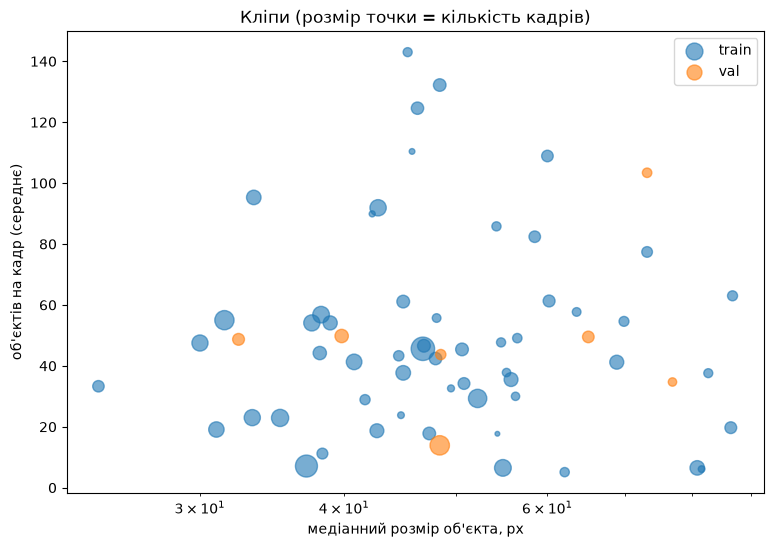

,min,median,max
frames,58.0,363.0,1424.0
objects_per_frame,5.1,44.2,143.0
median_size,24.5,48.1,86.8
small_%,0.0,18.1,73.1


top_class
car       36
person    24
motor      2
truck      1
Name: count, dtype: int64

,width,height,frames,objects_per_frame,median_size,small_%,top_class,top_class_%
video,,,,,,,,
uav0000086_00000_v,1344,756,464,49.8,39.8,28.5,person,95.7
uav0000117_02622_v,2720,1530,349,49.5,65.1,7.6,person,56.0
uav0000137_00458_v,2688,1512,233,103.4,73.2,0.6,person,38.6
uav0000182_00000_v,1344,756,363,48.7,32.4,49.2,motor,33.3
uav0000268_05773_v,3840,2160,978,13.9,48.4,13.9,car,64.0
uav0000305_00000_v,1904,1071,184,34.7,77.0,11.4,car,56.6
uav0000339_00001_v,1904,1071,275,43.7,48.5,21.3,person,45.6


In [42]:
fig, ax = plt.subplots(figsize=(9, 6))
for split, group in clips.groupby("split"):
    ax.scatter(group["median_size"], group["objects_per_frame"], s=group["frames"] / 5, alpha=0.6, label=split)
ax.set(xscale="log", xlabel="медіанний розмір об'єкта, px", ylabel="об'єктів на кадр (середнє)",
       title="Кліпи (розмір точки = кількість кадрів)")
ax.legend()
plt.show()

numeric = ["frames", "objects_per_frame", "median_size", "small_%"]
display(clips[numeric].agg(["min", "median", "max"]).T, clips["top_class"].value_counts())
clips[clips["split"] == "val"].drop(columns="split")

**Що бачимо:**
- кліпи дуже різні: довжина 58–1 424 кадри, 5–143 об'єкти на кадр, медіанний розмір 24–87 px, частка small 0–73%;
- 36 кліпів переважно з машинами, 24 — з людьми;
- val-кліпи покривають увесь діапазон, але один (`uav0000268`, 978 кадрів) — це третина val.

**Що робимо:** потрібна аугментація масштабу. Окрім загального val mAP рахуємо mAP по кожному val-кліпу.

### 3б. Роздільність кадрів у train, val і test

% кадрів за шириною.

In [43]:
test_images = pd.read_csv(DATA / "test_images.csv")
widths = pd.concat({"train": train_images["width"], "val": val_images["width"], "test": test_images["width"]})
width_groups = pd.cut(widths, WIDTH_BINS, labels=WIDTH_LABELS)

pd.crosstab(width_groups, widths.index.get_level_values(0), normalize="columns").mul(100).round(1)[["train", "val", "test"]]

col_0,train,val,test
width,,,
<900,0.0,0.0,8.4
900–1200,0.0,0.0,7.3
1200–1600,27.3,29.1,50.2
1600–2000,56.3,16.1,34.0
>2000,16.4,54.8,0.0


**Що бачимо:**
- у тесті всі кадри не ширші за 1920 px, і 16% з них менші за будь-який кадр train;
- у val 55% кадрів ширші за 2000 px, у тесті таких немає.

**Що робимо:** val не змінюємо, але додатково рахуємо mAP на 4 «тестоподібних» val-кліпах (ширина ≤ 1920). Аугментація масштабу потрібна й через різницю роздільностей.

## 4. Ігноровані зони й нецільові класи

### 4а. Скільки зон і яку площу кадру вони займають

Спершу по кадрах (як часто модель бачитиме зони під час навчання), потім по кліпах (у скількох сценах вони є). Площу рахуємо як частку зафарбованих пікселів маски, зменшеної в 4 рази, тож зони, що перекриваються, не рахуються двічі.

In [44]:
MASK_SCALE = 4


def zone_cover(images, zones):
    boxes = np.rint(zones[["x", "y", "w", "h"]].to_numpy() / MASK_SCALE).astype(int)
    boxes[:, :2] = boxes[:, :2].clip(min=0)
    cover = {}
    for image_id, rows in zones.groupby("image_id").indices.items():
        height = int(np.ceil(images.at[image_id, "height"] / MASK_SCALE))
        width = int(np.ceil(images.at[image_id, "width"] / MASK_SCALE))
        mask = np.zeros((height, width), dtype=bool)
        for x, y, w, h in boxes[rows]:
            mask[y:y + h, x:x + w] = True
        cover[image_id] = mask.mean() * 100
    return pd.Series(cover).reindex(images.index, fill_value=0.0)


def frame_zones(images, anns, split):
    zones = anns[anns["iscrowd"] == 1]
    frames = images[["video"]].copy()
    frames["split"] = split
    frames["zone_%"] = zone_cover(images, zones)
    frames["has_zone"] = frames.index.isin(zones["image_id"])
    return frames


def zone_summary(frames):
    with_zone = frames.loc[frames["has_zone"], "zone_%"]
    return pd.Series({
        "кадрів із зонами, %": frames["has_zone"].mean() * 100,
        "площа зон: медіана, %": with_zone.median(),
        "площа зон: 95-й перцентиль, %": with_zone.quantile(0.95),
        "площа зон: максимум, %": with_zone.max(),
    })


frames = pd.concat([frame_zones(train_images, train_anns, "train"), frame_zones(val_images, val_anns, "val")])
pd.DataFrame({split: zone_summary(group) for split, group in frames.groupby("split")}).round(1)

,train,val
"кадрів із зонами, %",74.7,50.4
"площа зон: медіана, %",1.6,1.4
"площа зон: 95-й перцентиль, %",11.3,9.3
"площа зон: максимум, %",38.0,10.3


In [45]:
clip_zones = frames.groupby("video").agg(frames_with_zones=("has_zone", "mean"))
clip_zones["frames_with_zones_%"] = clip_zones.pop("frames_with_zones") * 100
clip_zones["median_zone_%"] = frames[frames["has_zone"]].groupby("video")["zone_%"].median()

clips = clips.drop(columns=clip_zones.columns, errors="ignore").join(clip_zones.round(1))
clips.to_csv("clips.csv")

has_zones = clips["frames_with_zones_%"] > 0
display(has_zones.groupby(clips["split"]).agg(["sum", "size"]).rename(columns={"sum": "кліпів із зонами", "size": "усього кліпів"}))
clips.loc[has_zones, ["frames_with_zones_%", "median_zone_%"]].agg(["min", "median", "max"]).T

,кліпів із зонами,усього кліпів
split,,
train,50,56
val,5,7


,min,median,max
frames_with_zones_%,17.6,100.0,100.0
median_zone_%,0.1,1.6,26.2


**Що бачимо:**
- зони є на 75% кадрів train і в 50 з 56 кліпів; у кліпі із зонами вони майже на кожному кадрі;
- займають мало: медіана 1,6% площі кадру, 95% кадрів — до 11%, максимум 38%.

**Що робимо:** зафарбовування зон на train безпечне — кадри не перетворюються на суцільні сірі прямокутники.

### 4б. Розмічені об'єкти всередині зон

Якщо такі є, зафарбовування на train закриє їх разом із зоною.

In [55]:
def objects_inside_zones(anns):
    zones = anns.loc[anns["iscrowd"] == 1, ["image_id", "x", "y", "w", "h"]]
    obj = anns.loc[anns["iscrowd"] == 0, ["id", "image_id", "x", "y", "w", "h"]]
    pairs = obj.merge(zones, on="image_id", suffixes=("", "_z"))
    cx = pairs["x"] + pairs["w"] / 2
    cy = pairs["y"] + pairs["h"] / 2
    inside = ((cx >= pairs["x_z"]) & (cx <= pairs["x_z"] + pairs["w_z"])
              & (cy >= pairs["y_z"]) & (cy <= pairs["y_z"] + pairs["h_z"]))
    return pairs.loc[inside, ["id", "image_id"]].drop_duplicates("id")


def inside_summary(anns):
    n_inside = len(objects_inside_zones(anns))
    return pd.Series({"об'єктів із центром у зоні": n_inside,
                      "% від усіх об'єктів": n_inside / (anns["iscrowd"] == 0).sum() * 100})


pd.DataFrame({"train": inside_summary(train_anns), "val": inside_summary(val_anns)}).round(2)

,train,val
об'єктів із центром у зоні,12623.00,1229.00
% від усіх об'єктів,1.14,1.08


**Що бачимо:** 1,1% розмічених об'єктів (12,6 тис. у train) мають центр усередині ігнорованої зони.

**Що робимо:** зафарбовуємо зону, але повертаємо оригінальні пікселі всередині рамок розмічених об'єктів, щоб вони лишалися видимими (варіант b).

### 4в. Нецільові класи

Рядки — оригінальний клас VisDrone (`orig_category_id`), колонки — клас змагання або ігнорована зона. Train і val разом.

In [47]:
both = pd.concat([train_anns, val_anns])
target = both["category_id"].map(classes).where(both["iscrowd"] == 0, "ignored")

pd.crosstab(both["orig_category_id"], target, dropna=False).reindex(columns=CLASS_ORDER + ["ignored"], fill_value=0)

category_id,person,bicycle,car,van,truck,tricycle,bus,motor,ignored
orig_category_id,,,,,,,,,
0,0,0,0,0,0,0,0,0,530904
1,266709,0,0,0,0,0,0,0,0
2,112304,0,0,0,0,0,0,0,0
3,0,46277,0,0,0,0,0,0,0
4,0,0,537122,0,0,0,0,0,0
5,0,0,0,53782,0,0,0,0,0
6,0,0,0,0,31857,0,0,0,0
7,0,0,0,0,0,32107,0,0,0
8,0,0,0,0,0,14729,0,0,0


**Що бачимо:**
- pedestrian (1) і people (2) злито в `person`;
- tricycle (7) і awning-tricycle (8) злито в `tricycle`;
- ignored regions (0) і others (11) стали ігнорованими зонами; решта класів переходить один до одного.

**Що робимо:** нецільові об'єкти (others) обробляємо як ігноровані зони. Пам'ятаємо, що `person` неоднорідний (люди, що йдуть, і люди в інших позах), — перевіримо це в аналізі помилок.

## 5. Крок між кадрами

Лише train: з кожного кліпу беремо кожен k-й кадр. Рахуємо, скільки кадрів, рамок і унікальних об'єктів лишається, скільки рідкісних об'єктів губиться, і наскільки зсувається рамка того самого об'єкта за k кадрів (IoU = 1 означає, що кадри майже однакові).

In [48]:
train_frames = train_images[["video", "frame_id"]].copy()
train_frames["pos"] = train_frames.groupby("video")["frame_id"].rank(method="first").astype(int) - 1

train_obj = objects[objects["split"] == "train"].copy()
train_obj["pos"] = train_obj["image_id"].map(train_frames["pos"])
all_tracks = train_obj.drop_duplicates(["video", "track_id"])


def track_iou(obj, k):
    cols = ["video", "track_id", "pos", "x", "y", "w", "h"]
    later = obj[cols].assign(pos=obj["pos"] - k)
    p = obj[cols].merge(later, on=["video", "track_id", "pos"], suffixes=("", "_k"))
    ix = (np.minimum(p["x"] + p["w"], p["x_k"] + p["w_k"]) - np.maximum(p["x"], p["x_k"])).clip(lower=0)
    iy = (np.minimum(p["y"] + p["h"], p["y_k"] + p["h_k"]) - np.maximum(p["y"], p["y_k"])).clip(lower=0)
    inter = ix * iy
    return (inter / (p["w"] * p["h"] + p["w_k"] * p["h_k"] - inter)).median()

In [49]:
def step_stats(k):
    kept = train_obj[train_obj["pos"] % k == 0]
    kept_tracks = kept.drop_duplicates(["video", "track_id"])
    lost = all_tracks["class"].value_counts().sub(kept_tracks["class"].value_counts(), fill_value=0)
    return pd.Series({
        "кадрів": (train_frames["pos"] % k == 0).sum(),
        "рамок": len(kept),
        "унікальних об'єктів, %": len(kept_tracks) / len(all_tracks) * 100,
        "втрачено bus": lost.get("bus", 0),
        "втрачено truck": lost.get("truck", 0),
        "IoU через k кадрів (медіана)": track_iou(train_obj, k),
    })


steps = pd.DataFrame({k: step_stats(k) for k in (1, 2, 3, 5, 10, 20)}).T.rename_axis("крок")
steps.astype({"кадрів": int, "рамок": int, "втрачено bus": int, "втрачено truck": int}).round(3)

,кадрів,рамок,"унікальних об'єктів, %",втрачено bus,втрачено truck,IoU через k кадрів (медіана)
крок,,,,,,
1,24201,1105516,100.000,0,0,0.897
2,12114,553391,99.591,0,0,0.810
3,8090,370072,99.741,0,0,0.731
5,4868,222879,99.265,0,1,0.597
10,2446,112264,98.597,0,1,0.357
20,1238,57030,96.677,0,2,0.102


**Що бачимо:**
- сусідні кадри майже однакові: рамка того самого об'єкта через 1 кадр має IoU 0,90;
- при кроці 5 лишається 4 868 кадрів (у 5 разів менше), 99,3% унікальних об'єктів, усі 51 автобус, втрачено 1 вантажівку з 148; IoU через 5 кадрів 0,60 — кадри вже помітно різні.

**Що робимо:** беремо кожен 5-й кадр train. Val і test не проріджуємо.

## 6. Навчальний набір

Кожен 5-й train-кадр. Ігноровані зони зафарбовуємо сірим 114 (так Ultralytics заповнює порожні ділянки в `LetterBox`, `Mosaic` і `RandomPerspective`), пікселі всередині рамок об'єктів відновлюємо. Кадри з довшою стороною понад 1920 px зменшуємо до 1920 (максимум у тесті). Val не змінюємо.

Вихід: картинки й YOLO-мітки, `train_coco.json` для torchvision, `data.yaml` для Ultralytics.

In [ ]:
import os
import shutil
from concurrent.futures import ThreadPoolExecutor

from PIL import Image

STEP = 5
FILL = 114
MAX_SIDE = 1920
OUT = Path("/kaggle/working/hw2_prepared") if ON_KAGGLE else Path.cwd().parent.parent / "hw2_prepared"

selected = train_images[train_frames["pos"] % STEP == 0].copy()
selected["rel"] = selected["file_name"].map(lambda f: f"{Path(f).parent.name}/{Path(f).name}")
selected["scale"] = (MAX_SIDE / selected[["width", "height"]].max(axis=1)).clip(upper=1)


def pixel_boxes(anns):
    b = anns[["x", "y", "w", "h"]].to_numpy()
    corners = np.column_stack([np.floor(b[:, :2]), np.ceil(b[:, :2] + b[:, 2:])]).astype(int).clip(min=0)
    return {image_id: corners[rows] for image_id, rows in anns.groupby("image_id").indices.items()}


chosen = train_anns[train_anns["image_id"].isin(selected.index)]
zone_boxes = pixel_boxes(chosen[chosen["iscrowd"] == 1])
object_boxes = pixel_boxes(chosen[chosen["iscrowd"] == 0])

In [51]:
def prepare_frame(image_id):
    row = selected.loc[image_id]
    img = np.array(Image.open(DATA / "train" / "images" / row["rel"]).convert("RGB"))
    if image_id in zone_boxes:
        original = img.copy()
        for x0, y0, x1, y1 in zone_boxes[image_id]:
            img[y0:y1, x0:x1] = FILL
        for x0, y0, x1, y1 in object_boxes.get(image_id, []):
            img[y0:y1, x0:x1] = original[y0:y1, x0:x1]

    out = Image.fromarray(img)
    if row["scale"] < 1:
        size = (round(row["width"] * row["scale"]), round(row["height"] * row["scale"]))
        out = out.resize(size, Image.Resampling.BILINEAR)

    image_path = OUT / "images" / "train" / row["rel"]
    label_path = OUT / "labels" / "train" / Path(row["rel"]).with_suffix(".txt")
    image_path.parent.mkdir(parents=True, exist_ok=True)
    label_path.parent.mkdir(parents=True, exist_ok=True)
    out.save(image_path, quality=95)
    shutil.copyfile(DATA / "train" / "labels" / Path(row["rel"]).with_suffix(".txt"), label_path)


with ThreadPoolExecutor(max_workers=os.cpu_count()) as pool:
    list(pool.map(prepare_frame, selected.index))

In [52]:
coco_images = [
    {"id": int(r.Index), "file_name": f"images/train/{r.rel}", "video": r.video,
     "width": round(r.width * r.scale), "height": round(r.height * r.scale)}
    for r in selected.itertuples()
]

obj = chosen[chosen["iscrowd"] == 0].copy()
obj[["x", "y", "w", "h"]] = obj[["x", "y", "w", "h"]].mul(obj["image_id"].map(selected["scale"]), axis=0)
coco_anns = [
    {"id": int(a.id), "image_id": int(a.image_id), "category_id": int(a.category_id),
     "bbox": [a.x, a.y, a.w, a.h], "area": a.w * a.h, "iscrowd": 0}
    for a in obj.itertuples()
]
categories = [{"id": k, "name": v} for k, v in classes.items()]
(OUT / "train_coco.json").write_text(json.dumps({"images": coco_images, "annotations": coco_anns, "categories": categories}))

(OUT / "data.yaml").write_text(
    f"path: {OUT}\ntrain: images/train\nval: {DATA / 'val' / 'images'}\nnames: {json.dumps(CLASS_ORDER)}\n"
)

yolo_files = list((OUT / "labels" / "train").rglob("*.txt"))
pd.Series({
    "кадрів": len(selected),
    "із зафарбованими зонами": int(selected.index.isin(list(zone_boxes)).sum()),
    "зменшено до 1920": int((selected["scale"] < 1).sum()),
    "YOLO-файлів": len(yolo_files),
    "рамок у YOLO": sum(len(p.read_text().splitlines()) for p in yolo_files),
    "рамок у COCO": len(coco_anns),
})

кадрів                       4868
із зафарбованими зонами      3644
зменшено до 1920              803
YOLO-файлів                  4868
рамок у YOLO               222879
рамок у COCO               222879
dtype: int64

**Що бачимо:** записано 4 868 кадрів, з них 3 644 із зафарбованими зонами і 803 зменшених до 1920 px. Рамок у YOLO і в COCO однаково — 222 879, стільки ж, скільки в таблиці кроку 5.

**Що робимо:** цей набір — спільний для всіх моделей: YOLO-мітки й `data.yaml` для Ultralytics, `train_coco.json` для torchvision.

## 7. Візуальна перевірка набору

Кадри з готового набору, рамки з наших YOLO-міток: найщільніший кадр, кадр з найбільшими зонами, об'єкт усередині зони (варіант b) і зменшений 4K-кадр. Останні два збільшено навколо одного об'єкта.

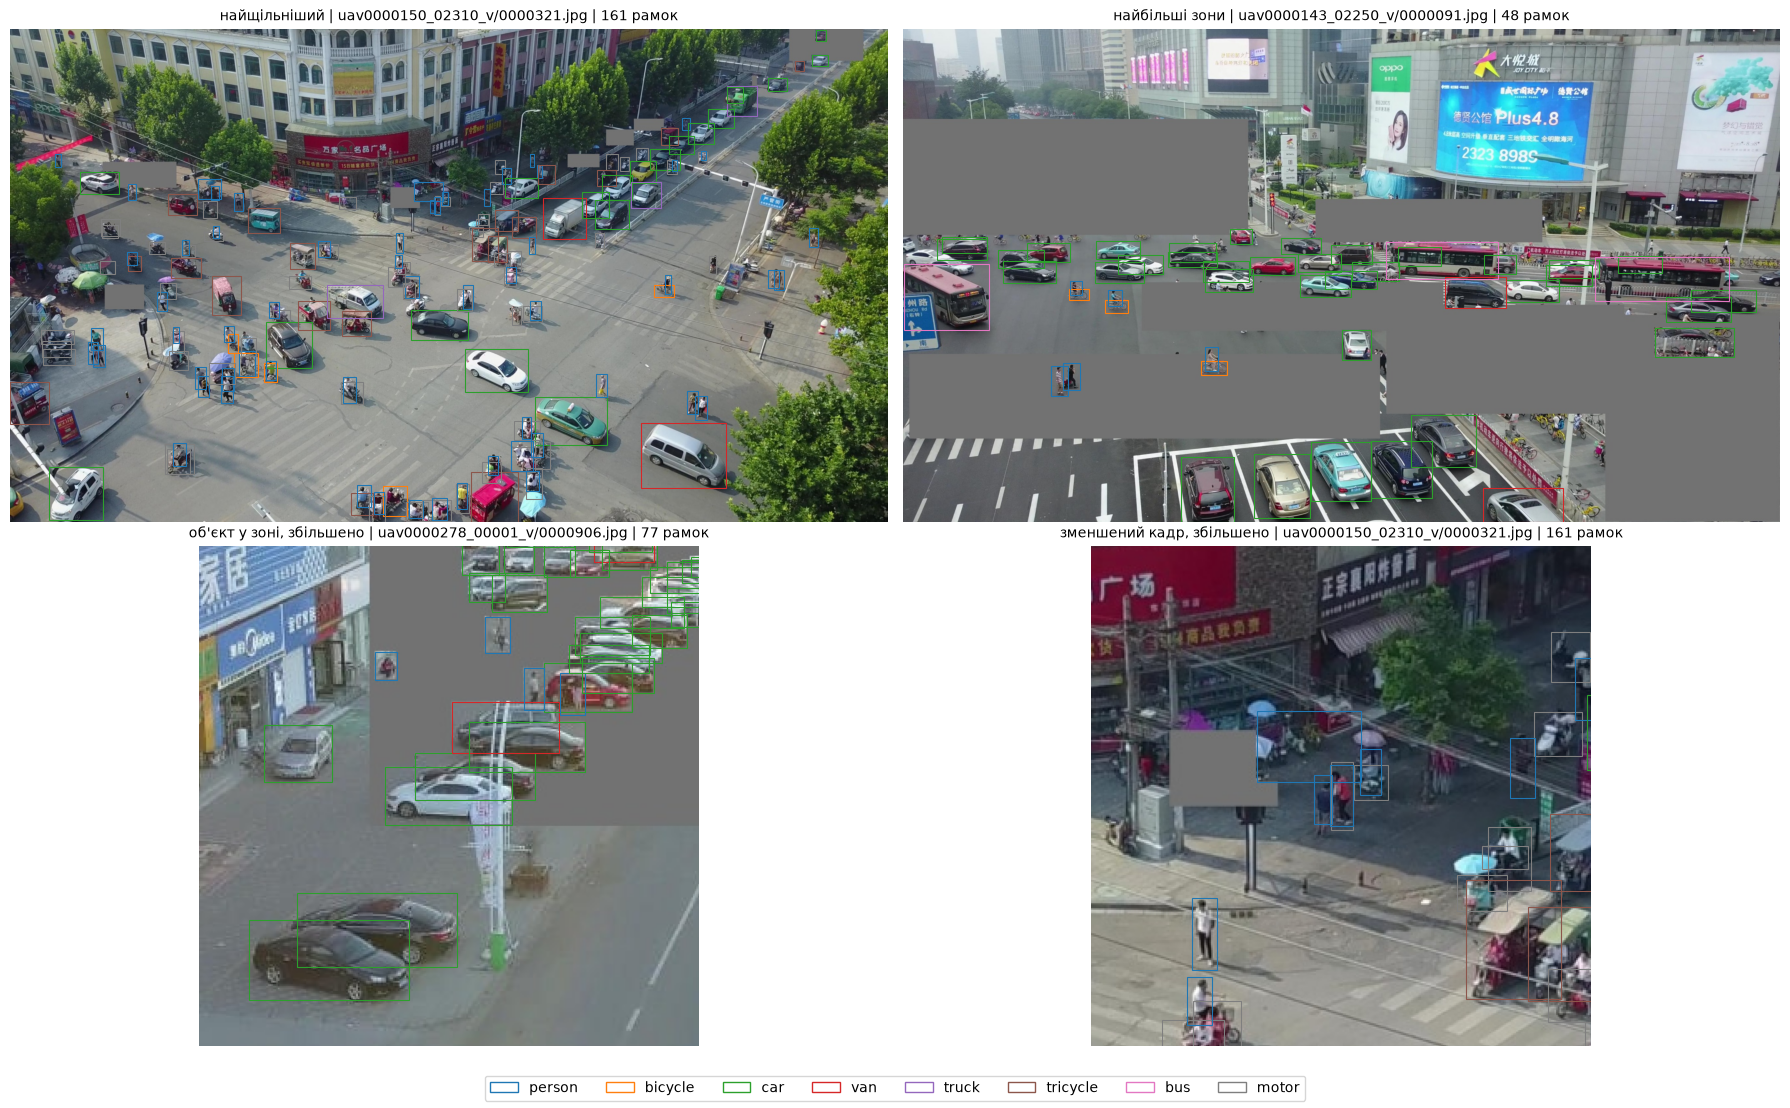

In [56]:
from matplotlib.patches import Patch, Rectangle

obj_by_id = obj.set_index("id")


def zoom_around(ann_id, margin=150):
    a = obj_by_id.loc[ann_id]
    cx, cy = a["x"] + a["w"] / 2, a["y"] + a["h"] / 2
    return cx - margin, cy - margin, cx + margin, cy + margin


def draw_prepared(ax, image_id, title, zoom=None):
    rel = selected.at[image_id, "rel"]
    img = Image.open(OUT / "images" / "train" / rel)
    labels = np.loadtxt(OUT / "labels" / "train" / Path(rel).with_suffix(".txt"), ndmin=2)
    width, height = img.size
    ax.imshow(img)
    for cls, cx, cy, w, h in labels:
        ax.add_patch(Rectangle(((cx - w / 2) * width, (cy - h / 2) * height), w * width, h * height,
                               fill=False, edgecolor=plt.cm.tab10(int(cls)), linewidth=0.8))
    if zoom:
        ax.set_xlim(zoom[0], zoom[2])
        ax.set_ylim(zoom[3], zoom[1])
    ax.set_title(f"{title} | {rel} | {len(labels)} рамок", fontsize=10)
    ax.axis("off")


boxes_per_frame = obj.groupby("image_id").size()
densest = boxes_per_frame.idxmax()
largest_zones = frames.loc[frames["split"] == "train", "zone_%"].reindex(selected.index).idxmax()

inside = objects_inside_zones(chosen)
inside_frame = inside["image_id"].value_counts().idxmax()
inside_id = inside.loc[inside["image_id"] == inside_frame, "id"].iloc[0]

downscaled = boxes_per_frame.reindex(selected.index[selected["scale"] < 1]).idxmax()
in_frame = obj[obj["image_id"] == downscaled]
middle_id = in_frame.loc[(in_frame["x"] - in_frame["x"].median()).abs().idxmin(), "id"]

cases = [
    (densest, "найщільніший", None),
    (largest_zones, "найбільші зони", None),
    (inside_frame, "об'єкт у зоні, збільшено", zoom_around(inside_id)),
    (downscaled, "зменшений кадр, збільшено", zoom_around(middle_id)),
]

fig, axes = plt.subplots(2, 2, figsize=(18, 11))
for ax, case in zip(axes.flat, cases):
    draw_prepared(ax, *case)
legend = [Patch(edgecolor=plt.cm.tab10(i), fill=False, label=name) for i, name in enumerate(CLASS_ORDER)]
fig.legend(handles=legend, loc="lower center", ncol=len(legend))
plt.tight_layout(rect=(0, 0.04, 1, 1))
plt.savefig("prepared_check.png", dpi=120)
plt.show()

**Що бачимо:**
- рамки щільно облягають об'єкти без систематичного зсуву, зокрема на зменшеному кадрі;
- сірі зони лежать на натовпі й парковках, розмічені об'єкти в зонах видно у «вікнах»;
- розмітка не завжди послідовна: частина машин на парковці розмічена, хоча парковка позначена як ігнорована зона.

**Що робимо:** конвертацію, маскування і зменшення вважаємо перевіреними.

## Джерела

- Опис даних змагання (формати, ігноровані зони, рекомендація маскувати їх під час навчання): https://www.kaggle.com/competitions/multiple-object-video-detection-hw-2-ucu-ai-2026/data
- VisDrone — Du et al., arXiv:2001.06303: оригінальні класи (pedestrian і person — виноска 6), протокол оцінювання (AP@[.5:.95], AR при 500 детекціях), дисбаланс класів.
- COCO detection metrics (межі small/medium/large: 32² і 96² px²): https://cocodataset.org/#detection-eval
- Ultralytics, `ultralytics/data/augment.py` — значення 114 для порожніх ділянок у `LetterBox`, `Mosaic`, `RandomPerspective` (звідси колір заливки); `ultralytics/data/base.py`, `load_image` — довша сторона кадру стискається до `imgsz` (звідси аналіз 2г і зменшення до 1920): https://github.com/ultralytics/ultralytics
- Бібліотеки: pandas, NumPy, Matplotlib, Pillow.

**Наші рішення (не з джерел):** крок 5 між кадрами, варіант (b) — відновлення пікселів розмічених об'єктів у зонах, поріг 8 px у 2г (оцінка за кроком найдрібнішої сітки ознак), межа 1920 px для «тестоподібних» кадрів, обчислення площі зон через маску.